In [14]:
from nes.dists import XDiagNormal, XDiagNormalAdaptive, XDiagNormalSchaulLR
from nes.models import NPolynome, Spherical
import numpy as np
from matplotlib import pyplot as plt

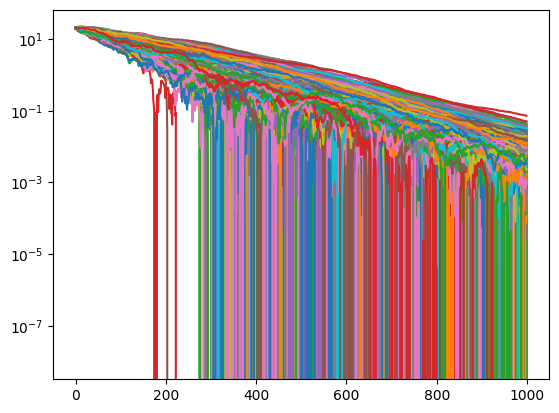

In [15]:
d = 1024
dist = XDiagNormalAdaptive.from_dimensions(d)
dist.set_init_params(np.array([20] * d + [20] * d, dtype=np.float64))
params = []
n = 4 * d
for _ in range(1000):
    samples = dist.get_samples(n)
    fitness = (-samples**2).sum(axis=1).reshape(-1, 1)
    # print(samples.T, fitness.T)
    # print(dist._params, dist._gradient(samples, fitness), dist._inverse_fisher(samples))
    params.append(dist._params.copy())
    dist.param_variation(samples, fitness)
params = np.array(params)
for i in range(d):
    plt.semilogy(params[:, i], label=str(i))
#plt.legend()

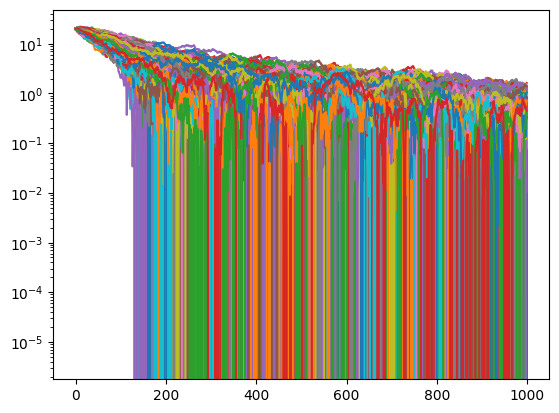

In [16]:
d = 1024
dist = XDiagNormalSchaulLR.from_dimensions(d)
dist.set_init_params(np.array([20] * d + [20] * d, dtype=np.float64))
params = []
n = 4 * d
for _ in range(1000):
    samples = dist.get_samples(n)
    fitness = (-samples**2).sum(axis=1).reshape(-1, 1)
    # print(samples.T, fitness.T)
    # print(dist._params, dist._gradient(samples, fitness), dist._inverse_fisher(samples))
    params.append(dist._params.copy())
    dist.param_variation(samples, fitness)
params = np.array(params)
for i in range(d):
    plt.semilogy(params[:, i], label=str(i))
#plt.legend()

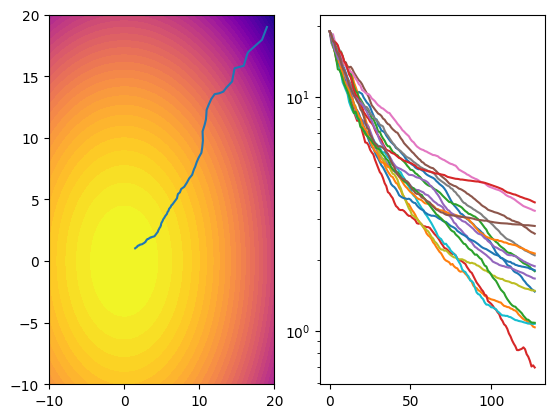

In [17]:
d = 16
model = NPolynome(np.array(
    [
        [0] * d,
        [0] * d,
        [-1] * d,
    ]
    ))
model.lower = [-10.0]*d
model.upper = [20.0]*d
fig, ax = plt.subplots(1, 2)
model.plot_fitness(ax[0], model.lower, model.upper)
dist = XDiagNormal.from_model(model)
dist.set_init_params(np.array(model.upper + model.upper)*0.95)
params = []
n = 100 * d
for _ in range(128):
    samples = dist.get_samples(n)
    fitness = model.evaluate_samples(samples)
    params.append(dist._params.copy())
    dist.param_variation(samples, fitness)
params = np.array(params)
x = params[:, 0]
y = params[:, 1]
ax[0].plot(x, y)
for i in range(d):
    ax[1].semilogy(params[:, i], label=str(i))
plt.show()

/home/christof/nes/nes/dists/xdiag_normal.py:65: RuntimeWarning: invalid value encountered in divide
  weighted_gradients = gradients * (adjusted_fitness / adjusted_fitness.sum())


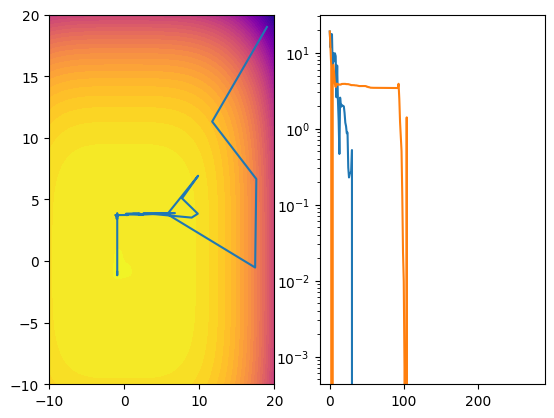

In [18]:
d = 2
params = np.zeros((10, d))
params[2, :] = 1
params[4, :] = -1
params[1, :] = -1
model = NPolynome(params)
model.lower = [-10.0]*d
model.upper = [20.0]*d
fig, ax = plt.subplots(1, 2)
model.plot_fitness(ax[0], model.lower, model.upper)
dist = XDiagNormal.from_model(model)
dist.set_init_params(np.array(model.upper + model.upper)*0.95)
params = []
n = 4 * d
for _ in range(1024):
    samples = dist.get_samples(n)
    fitness = model.evaluate_samples(samples)
    params.append(dist._params.copy())
    dist.param_variation(samples, fitness)
params = np.array(params)
x = params[:, 0]
y = params[:, 1]
ax[0].plot(x, y)
for i in range(d):
    ax[1].semilogy(params[:, i], label=str(i))
plt.show()

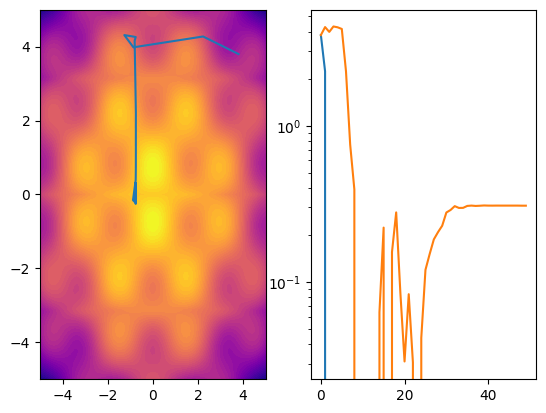

In [19]:
dim = 2
params = np.zeros((3, dim))
params[2, :] = -0.05
parabola = NPolynome(params)
spherical = Spherical(2, 1)
model = parabola + spherical
model.upper = np.array([5, 5], dtype=np.float64)
model.lower = np.array([-5, -5], dtype=np.float64)
fig, ax = plt.subplots(1, 2)
model.plot_fitness(ax[0], model.lower, model.upper)
dist = XDiagNormal.from_model(model)
dist.set_init_params(np.array([4, 4, 10, 10])*0.95)
params = []
n = 4 * d
for _ in range(50):
    samples = dist.get_samples(n)
    fitness = model.evaluate_samples(samples)
    params.append(dist._params.copy())
    dist.param_variation(samples, fitness)
params = np.array(params)
x = params[:, 0]
y = params[:, 1]
ax[0].plot(x, y)
for i in range(dim):
    ax[1].semilogy(params[:, i], label=str(i))
plt.show()